In [34]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [35]:
number_of_realisations = 100
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.97219e24 * 9.50 

surface_radius = 1.03 * 9.50**0.29  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [36]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [37]:
eos_models = get_eos_models()

H2O_rg = Species.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_basalt_dixon95"],
)
H2_rg = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"])
CO_rg = Species.create_gas(
    "CO",
    activity=eos_models["CO_cs_shi92"],
    solubility=solubility_models["CO_basalt_yoshioka19"],
)
CO2_rg = Species.create_gas(
    "CO2",
    activity=eos_models["CO2_cs_shi92"],
    solubility=solubility_models["CO2_basalt_dixon95"],
)
CH4_rg = Species.create_gas(
    "CH4",
    activity=eos_models["CH4_cs_shi92"],
    solubility=solubility_models["CH4_basalt_ardia13"],
)

realspecies_withsols = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))


## Hydrogen fraction

Where does saturation occur

In [38]:
log10_H_frac = np.full(number_of_realisations, 0)

log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.linspace(-6, 0, number_of_realisations)


h_kg = ((10**log10_H_frac) / 100) * planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
}


In [39]:
sub_neptune = Planet(
        surface_temperature=surface_temperature,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction,
    )

In [40]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)
model = InteriorAtmosphere(realspecies_withsols)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

output_model = model.output

# Write the complete solution to Excel
file = output_model.to_excel("FILE10")

# Write the data to a pickle file with dataframes
output_model.to_pickle("FILE10")


[22:54:22 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[22:54:22 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:54:22 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[22:54:22 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[22:54:25 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[22:54:25 - atmodeller.classes             - INFO     ] - Solver steps (max) = 172
[22:54:25 - atmodeller.output              - INFO 

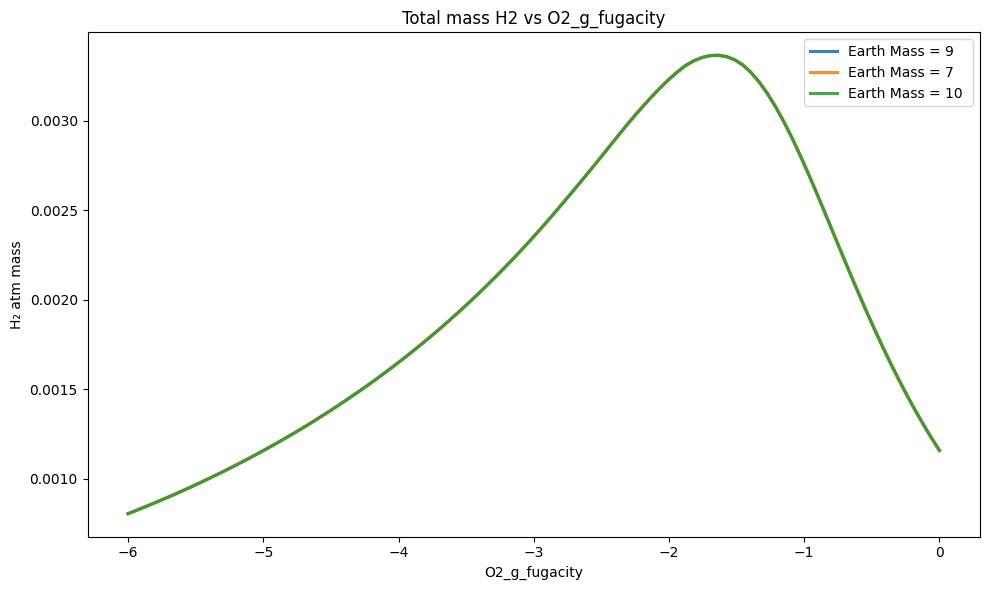

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

files = ['FILE8.xlsx', 'FILE9.xlsx', 'FILE10.xlsx']

fig, ax = plt.subplots(figsize=(10, 6))

for file in files:
    # Load sheets
    H2 = pd.read_excel(file, sheet_name='H2_g')
    O2 = pd.read_excel(file, sheet_name='O2_g')
    planet = pd.read_excel(file, sheet_name='planet')
    atm = pd.read_excel(file, sheet_name='atmosphere')

    mass = planet['planet_mass'][0]

    # Extract x/y
    z = atm['mass']
    x = O2['log10dIW_P']
    y = H2['atmosphere_mass'] / z



    # If only 1 temperature exists, use it as label
    # Otherwise the label will display all of them (modify if needed)

    # Plot line for this temperature
    ax.plot(
        x,
        y,
        lw=2.2,
        alpha=0.9,
        label=f"Earth Mass = {round(mass / 5.97219e24)} "
    )

# --- Labels ---
ax.set_xlabel("O2_g_fugacity")
ax.set_ylabel("H₂ atm mass")
ax.set_title("Total mass H2 vs O2_g_fugacity")
ax.legend()

plt.tight_layout()
plt.savefig("TAAAA.png", dpi=300)
plt.show()
